# Legacy research: testing the original models on local CSVs

**This notebook is not the serving or release-validation workflow.** Its name-only column mapping does not repair the first-packet defect or shuffled flags. Saved outputs are historical. Use `tools/eval_lab.py` to study repaired legacy CSVs, and `release_validation.ipynb` / `tools/train_release.py` for causal features, whole-session splits and the evaluated default bundle.

---
# PART 0 — Setup and shared helpers
Both models read the **same** CSV files in the **same** way, so the loading steps now live in **one function**, `load_local(pattern)`:

1. read every CSV that matches the pattern (e.g. `"../localdata/*.csv"`)
2. strip spaces from the headers (CIC headers often start with a space)
3. add `source_file` (which CSV each row came from)
4. warn if the files do not have the same columns
5. rename the CIC names to the training names (`Flow Duration` → `flow duration`) with `rename_map`
6. add the duplicate column `fwd header length.1` that the RF was trained with

**Examples:** `load_local("../localdata/*.csv")` → all files (RF part) · `load_local("../localdata/Benign.pcap_Flow.csv")` → one file (IF part) · `load_local(path, rename=False)` → keep the raw CIC names.

`to_features(df)` keeps only the 27 columns the IF was trained on.

In [1]:
import glob,joblib, os,pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import roc_auc_score, average_precision_score
import sys
sys.path.append("..")
sys.path.append("../src")
from evaluation_multiclass import (
    evaluate_multiclass,
    plot_confusion_matrix_multiclass,
    plot_per_class_metric,
)


In [2]:

rename_map = {
    'Dst Port': 'destination port',
    'Flow Duration': 'flow duration',
    'Tot Fwd Pkts': 'total fwd packets',
    'Tot Bwd Pkts': 'total backward packets',
    'TotLen Fwd Pkts': 'total length of fwd packets',
    'TotLen Bwd Pkts': 'total length of bwd packets',

    'Fwd Pkt Len Max': 'fwd packet length max',
    'Fwd Pkt Len Min': 'fwd packet length min',
    'Fwd Pkt Len Mean': 'fwd packet length mean',
    'Fwd Pkt Len Std': 'fwd packet length std',
    'Bwd Pkt Len Max': 'bwd packet length max',
    'Bwd Pkt Len Min': 'bwd packet length min',
    'Bwd Pkt Len Mean': 'bwd packet length mean',
    'Bwd Pkt Len Std': 'bwd packet length std',

    'Flow Byts/s': 'flow bytes/s',
    'Flow Pkts/s': 'flow packets/s',
    'Flow IAT Mean': 'flow iat mean',
    'Flow IAT Std': 'flow iat std',
    'Flow IAT Max': 'flow iat max',
    'Flow IAT Min': 'flow iat min',

    'Fwd IAT Tot': 'fwd iat total',
    'Fwd IAT Mean': 'fwd iat mean',
    'Fwd IAT Std': 'fwd iat std',
    'Fwd IAT Max': 'fwd iat max',
    'Fwd IAT Min': 'fwd iat min',

    'Bwd IAT Tot': 'bwd iat total',
    'Bwd IAT Mean': 'bwd iat mean',
    'Bwd IAT Std': 'bwd iat std',
    'Bwd IAT Max': 'bwd iat max',
    'Bwd IAT Min': 'bwd iat min',

    'Fwd PSH Flags': 'fwd psh flags',
    'Bwd PSH Flags': 'bwd psh flags',
    'Fwd URG Flags': 'fwd urg flags',
    'Bwd URG Flags': 'bwd urg flags',

    'Fwd Header Len': 'fwd header length',
    'Bwd Header Len': 'bwd header length',

    'Fwd Pkts/s': 'fwd packets/s',
    'Bwd Pkts/s': 'bwd packets/s',

    'Pkt Len Min': 'min packet length',
    'Pkt Len Max': 'max packet length',
    'Pkt Len Mean': 'packet length mean',
    'Pkt Len Std': 'packet length std',
    'Pkt Len Var': 'packet length variance',

    'FIN Flag Cnt': 'fin flag count',
    'SYN Flag Cnt': 'syn flag count',
    'RST Flag Cnt': 'rst flag count',
    'PSH Flag Cnt': 'psh flag count',
    'ACK Flag Cnt': 'ack flag count',
    'URG Flag Cnt': 'urg flag count',
    'CWE Flag Count': 'cwe flag count',
    'ECE Flag Cnt': 'ece flag count',

    'Down/Up Ratio': 'down/up ratio',
    'Pkt Size Avg': 'average packet size',
    'Fwd Seg Size Avg': 'avg fwd segment size',
    'Bwd Seg Size Avg': 'avg bwd segment size',

    'Fwd Byts/b Avg': 'fwd avg bytes/bulk',
    'Fwd Pkts/b Avg': 'fwd avg packets/bulk',
    'Fwd Blk Rate Avg': 'fwd avg bulk rate',
    'Bwd Byts/b Avg': 'bwd avg bytes/bulk',
    'Bwd Pkts/b Avg': 'bwd avg packets/bulk',
    'Bwd Blk Rate Avg': 'bwd avg bulk rate',

    'Subflow Fwd Pkts': 'subflow fwd packets',
    'Subflow Fwd Byts': 'subflow fwd bytes',
    'Subflow Bwd Pkts': 'subflow bwd packets',
    'Subflow Bwd Byts': 'subflow bwd bytes',

    'Init Fwd Win Byts': 'init_win_bytes_forward',
    'Init Bwd Win Byts': 'init_win_bytes_backward',

    'Active Mean': 'active mean',
    'Active Std': 'active std',
    'Active Max': 'active max',
    'Active Min': 'active min',
    'Idle Mean': 'idle mean',
    'Idle Std': 'idle std',
    'Idle Max': 'idle max',
    'Idle Min': 'idle min',
     "Fwd Act Data Pkts": "act_data_pkt_fwd",
    "Fwd Seg Size Min": "min_seg_size_forward"
}





In [14]:
# ---------- SHARED LOADER (used by BOTH the RF part and the IF part) ----------
def load_local(pattern, exclude=None, rename=True, verbose=True):
    """Shared loader for RF and IF.
    pattern : glob, e.g. "../localdata/*.csv"
    exclude : text (or list of texts); files whose NAME contains it are skipped, e.g. exclude="benign"
    rename  : True -> rename CIC names to the training names + add 'fwd header length.1'
    """
    files = sorted(glob.glob(pattern))
    if exclude:
        words = [exclude] if isinstance(exclude, str) else list(exclude)
        skipped = [f for f in files if any(w.lower() in os.path.basename(f).lower() for w in words)]
        files = [f for f in files if f not in skipped]
        if verbose and skipped:
            print("Skipped:", [os.path.basename(f) for f in skipped])
    assert files, f"No CSV files found for {pattern} (exclude={exclude})"

    frames = []
    for f in files:
        d = pd.read_csv(f, low_memory=False, encoding="latin-1")
        d.columns = d.columns.str.strip()
        d["source_file"] = os.path.basename(f)
        frames.append(d)
        if verbose:
            print(f"{os.path.basename(f):40s} {d.shape}")

    base = set(frames[0].columns)
    for f, d in zip(files, frames):
        diff = set(d.columns) ^ base
        if diff:
            print("Column mismatch in", os.path.basename(f), "->", diff)

    df = pd.concat(frames, ignore_index=True)

    if rename:
        df = df.rename(columns=rename_map)
        if "fwd header length" in df.columns and "fwd header length.1" not in df.columns:
            df["fwd header length.1"] = df["fwd header length"]

    if verbose:
        print("Combined:", df.shape)
    return df


In [15]:
def to_features(df):
    """Keep exactly the model's features, force numeric, turn +-inf into NaN (the model's preprocessor fills NaN with train medians)."""
    missing = [f for f in FEATURES if f not in df.columns]
    assert not missing, f"Missing model features: {missing}"
    X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
    return X.replace([np.inf, -np.inf], np.nan)

# PART A — Random Forest (RF) tested on the local dataset
## A1. Load the RF model and inspect what is inside

In [16]:

rf = joblib.load("../models/random_forest_final.joblib")

In [17]:
print(type(rf))

<class 'dict'>


In [18]:
if isinstance(rf, dict):
    print("\nKeys in saved model:")
    for key, value in rf.items():
        print(f"{key}: {type(value)}")
else:
    print("The saved object is the estimator itself.")


Keys in saved model:
model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
label_encoder: <class 'sklearn.preprocessing._label.LabelEncoder'>


In [19]:
rf_model = rf["model"]
rf_encoder = rf["label_encoder"]

print("Model:", type(rf_model))
print("Number of features:", rf_model.n_features_in_)
print("Number of classes:", rf_model.n_classes_)

print("\nAttack classes:")
print(rf_encoder.classes_)

Model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Number of features: 78
Number of classes: 14

Attack classes:
['Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']


In [20]:
if hasattr(rf_model, "feature_names_in_"):
    rf_features = list(rf_model.feature_names_in_)
    print("RF feature count:", len(rf_features))
    print(rf_features)
else:
    print("No feature names saved in the estimator.")
    print("We need the feature list from the training code.")

RF feature count: 78
['destination port', 'flow duration', 'total fwd packets', 'total backward packets', 'total length of fwd packets', 'total length of bwd packets', 'fwd packet length max', 'fwd packet length min', 'fwd packet length mean', 'fwd packet length std', 'bwd packet length max', 'bwd packet length min', 'bwd packet length mean', 'bwd packet length std', 'flow bytes/s', 'flow packets/s', 'flow iat mean', 'flow iat std', 'flow iat max', 'flow iat min', 'fwd iat total', 'fwd iat mean', 'fwd iat std', 'fwd iat max', 'fwd iat min', 'bwd iat total', 'bwd iat mean', 'bwd iat std', 'bwd iat max', 'bwd iat min', 'fwd psh flags', 'bwd psh flags', 'fwd urg flags', 'bwd urg flags', 'fwd header length', 'bwd header length', 'fwd packets/s', 'bwd packets/s', 'min packet length', 'max packet length', 'packet length mean', 'packet length std', 'packet length variance', 'fin flag count', 'syn flag count', 'rst flag count', 'psh flag count', 'ack flag count', 'urg flag count', 'cwe flag co

In [21]:
print("RF c?lasses:", rf_model.classes_)
print("Encoder classes:", rf_encoder.classes_)

RF c?lasses: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]
Encoder classes: ['Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']


## A2. Load the local CSV files

In [22]:
local = load_local("../localdata/*.csv",exclude="Benign") #make sure that the benign file not in the folder



Skipped: ['Benign-Scenarios.csv', 'Benign.pcap_Flow.csv']
Bot.pcap_Flow.csv                        (31, 85)
DoS-GoldenEye-2nd.pcap_Flow.csv          (8863, 85)
DoS-Slowloris.pcap_Flow.csv              (3076, 85)
FTP_Patator.pcap_Flow_labeled.csv        (21, 85)
PortScan.pcap_Flow.csv                   (153, 85)
ddos_hping3.pcap_Flow_labeled.csv        (4396, 85)
heartbleed_lab.pcap_Flow.csv             (8, 85)
infilteration.pcap_Flow_labeled.csv      (65820, 85)
Combined: (82368, 86)


## A3. Explore the local dataset

In [23]:

print("Dataset shape:", local.shape)

print("\nFirst 5 rows:")
display(local.head())

print("\nColumn names:")
print(local.columns.tolist())

print("\nData types:")
print(local.dtypes.to_string())

print("\nMissing values per column:")
print(
    local.isna().sum()
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
)

print("\nLabels:")
print(local["Label"].value_counts(dropna=False))


Dataset shape: (82368, 86)

First 5 rows:


,Flow ID,Src IP,Src Port,Dst IP,destination port,Protocol,Timestamp,flow duration,total fwd packets,total backward packets,...,active std,active max,active min,idle mean,idle std,idle max,idle min,Label,source_file,fwd header length.1
0,192.168.141.100-192.168.177.100-59772-80-6,192.168.141.100,59772.0,192.168.177.100,80,6,27/10/2026 01:45:28 PM,42960,4,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot,Bot.pcap_Flow.csv,128
1,192.168.141.100-192.168.177.100-56500-80-6,192.168.141.100,56500.0,192.168.177.100,80,6,27/10/2026 01:45:18 PM,41867,4,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot,Bot.pcap_Flow.csv,128
2,192.168.141.100-192.168.177.100-56498-80-6,192.168.141.100,56498.0,192.168.177.100,80,6,27/10/2026 01:45:13 PM,41857,4,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot,Bot.pcap_Flow.csv,128
3,192.168.141.100-192.168.177.100-35954-80-6,192.168.141.100,35954.0,192.168.177.100,80,6,27/10/2026 01:45:33 PM,42524,4,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot,Bot.pcap_Flow.csv,128
4,192.168.141.100-192.168.177.100-48960-80-6,192.168.141.100,48960.0,192.168.177.100,80,6,27/10/2026 01:46:08 PM,41585,4,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Bot,Bot.pcap_Flow.csv,128



Column names:
['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'destination port', 'Protocol', 'Timestamp', 'flow duration', 'total fwd packets', 'total backward packets', 'total length of fwd packets', 'total length of bwd packets', 'fwd packet length max', 'fwd packet length min', 'fwd packet length mean', 'fwd packet length std', 'bwd packet length max', 'bwd packet length min', 'bwd packet length mean', 'bwd packet length std', 'flow bytes/s', 'flow packets/s', 'flow iat mean', 'flow iat std', 'flow iat max', 'flow iat min', 'fwd iat total', 'fwd iat mean', 'fwd iat std', 'fwd iat max', 'fwd iat min', 'bwd iat total', 'bwd iat mean', 'bwd iat std', 'bwd iat max', 'bwd iat min', 'fwd psh flags', 'bwd psh flags', 'fwd urg flags', 'bwd urg flags', 'fwd header length', 'bwd header length', 'fwd packets/s', 'bwd packets/s', 'min packet length', 'max packet length', 'packet length mean', 'packet length std', 'packet length variance', 'fin flag count', 'syn flag count', 'rst flag count', 'psh

In [24]:
local.info()

<class 'pandas.DataFrame'>
RangeIndex: 82368 entries, 0 to 82367
Data columns (total 86 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Flow ID                      82367 non-null  str    
 1   Src IP                       82368 non-null  str    
 2   Src Port                     82368 non-null  float64
 3   Dst IP                       82368 non-null  str    
 4   destination port             82368 non-null  int64  
 5   Protocol                     82368 non-null  int64  
 6   Timestamp                    82368 non-null  str    
 7   flow duration                82368 non-null  int64  
 8   total fwd packets            82368 non-null  int64  
 9   total backward packets       82368 non-null  int64  
 10  total length of fwd packets  82368 non-null  float64
 11  total length of bwd packets  82368 non-null  float64
 12  fwd packet length max        82368 non-null  float64
 13  fwd packet length min      

## A4. Match the local column names to the RF feature names (check only after using the load_local fn)

In [25]:
rf_model = rf["model"]

expected = list(rf_model.feature_names_in_)

missing = [c for c in expected if c not in local.columns]
extra = [c for c in local.columns if c not in expected]

print("Number of RF features:", len(expected))
print("\nExpected RF features:")
print(expected)

print("\nMissing features:", missing)
print("\nExtra local columns:", extra)

Number of RF features: 78

Expected RF features:
['destination port', 'flow duration', 'total fwd packets', 'total backward packets', 'total length of fwd packets', 'total length of bwd packets', 'fwd packet length max', 'fwd packet length min', 'fwd packet length mean', 'fwd packet length std', 'bwd packet length max', 'bwd packet length min', 'bwd packet length mean', 'bwd packet length std', 'flow bytes/s', 'flow packets/s', 'flow iat mean', 'flow iat std', 'flow iat max', 'flow iat min', 'fwd iat total', 'fwd iat mean', 'fwd iat std', 'fwd iat max', 'fwd iat min', 'bwd iat total', 'bwd iat mean', 'bwd iat std', 'bwd iat max', 'bwd iat min', 'fwd psh flags', 'bwd psh flags', 'fwd urg flags', 'bwd urg flags', 'fwd header length', 'bwd header length', 'fwd packets/s', 'bwd packets/s', 'min packet length', 'max packet length', 'packet length mean', 'packet length std', 'packet length variance', 'fin flag count', 'syn flag count', 'rst flag count', 'psh flag count', 'ack flag count', 'u

## A5. Save the true labels, then drop non-feature columns

In [26]:
y_true = local['Label'].copy()
y_true_clean = y_true.replace({"DoS-Slowloris": "DoS slowloris"})



In [27]:
drop_cols = [
    'Flow ID',
    'Src IP',
    'Src Port',
    'Dst IP',
    'Protocol',
    'Timestamp',
    'Label',
    'source_file'

]



In [28]:
local = local.drop(columns=drop_cols, errors='ignore')

In [29]:
local.head(5)

,destination port,flow duration,total fwd packets,total backward packets,total length of fwd packets,total length of bwd packets,fwd packet length max,fwd packet length min,fwd packet length mean,fwd packet length std,...,min_seg_size_forward,active mean,active std,active max,active min,idle mean,idle std,idle max,idle min,fwd header length.1
0,80,42960,4,3,57.0,1383.0,57.0,0.0,14.25,28.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128
1,80,41867,4,3,57.0,1383.0,57.0,0.0,14.25,28.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128
2,80,41857,4,3,57.0,1383.0,57.0,0.0,14.25,28.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128
3,80,42524,4,3,57.0,1383.0,57.0,0.0,14.25,28.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128
4,80,41585,4,3,57.0,1383.0,57.0,0.0,14.25,28.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128


In [30]:
rf_model = rf["model"]

expected = list(rf_model.feature_names_in_)

missing = [c for c in expected if c not in local.columns]
extra = [c for c in local.columns if c not in expected]

print("Number of RF features:", len(expected))
print("\nExpected RF features:")
print(expected)

print("\nMissing features:", missing)
print("\nExtra local columns:", extra)

Number of RF features: 78

Expected RF features:
['destination port', 'flow duration', 'total fwd packets', 'total backward packets', 'total length of fwd packets', 'total length of bwd packets', 'fwd packet length max', 'fwd packet length min', 'fwd packet length mean', 'fwd packet length std', 'bwd packet length max', 'bwd packet length min', 'bwd packet length mean', 'bwd packet length std', 'flow bytes/s', 'flow packets/s', 'flow iat mean', 'flow iat std', 'flow iat max', 'flow iat min', 'fwd iat total', 'fwd iat mean', 'fwd iat std', 'fwd iat max', 'fwd iat min', 'bwd iat total', 'bwd iat mean', 'bwd iat std', 'bwd iat max', 'bwd iat min', 'fwd psh flags', 'bwd psh flags', 'fwd urg flags', 'bwd urg flags', 'fwd header length', 'bwd header length', 'fwd packets/s', 'bwd packets/s', 'min packet length', 'max packet length', 'packet length mean', 'packet length std', 'packet length variance', 'fin flag count', 'syn flag count', 'rst flag count', 'psh flag count', 'ack flag count', 'u

## A6. Build `X_test` (same order, numeric, no NaN/inf)

In [31]:
expected_features = list(rf["model"].feature_names_in_)

# Select columns in exactly the order used during training
X_test = local.reindex(columns=expected_features)

In [32]:

# Convert features to numeric
X_test = X_test.apply(pd.to_numeric, errors="coerce")
X_test = X_test.replace([np.inf, -np.inf], np.nan)

In [33]:
# Keep rows without missing feature values
valid_rows = X_test.notna().all(axis=1)
X_test_clean = X_test.loc[valid_rows]

print("Expected features:", len(expected_features))
print("Test features:", X_test_clean.shape[1])
print("Feature names match:", list(X_test_clean.columns) == expected_features)

Expected features: 78
Test features: 78
Feature names match: True


In [34]:
y_true_clean = y_true.loc[valid_rows]

## A7. Predict with the RF model

In [35]:
predictions = rf_model.predict(X_test_clean)

predicted_labels = rf["label_encoder"].inverse_transform(predictions)

results = pd.DataFrame({
    "Actual Label": y_true_clean,
    "Predicted Label": predicted_labels
})

print(results.head(-30))

       Actual Label   Predicted Label
0               Bot  DoS Slowhttptest
1               Bot  DoS Slowhttptest
2               Bot  DoS Slowhttptest
3               Bot  DoS Slowhttptest
4               Bot  DoS Slowhttptest
...             ...               ...
82331  Infiltration          DoS Hulk
82332  Infiltration          DoS Hulk
82333  Infiltration          DoS Hulk
82334  Infiltration          DoS Hulk
82335  Infiltration          DoS Hulk

[73314 rows x 2 columns]


In [36]:
# Compare actual and predicted label distributions
print("Actual labels:")
print(y_true_clean.value_counts())

print("\nPredicted labels:")
print(pd.Series(predicted_labels).value_counts())

print("\nSample comparisons:")
display(results.sample(min(10, len(results)), random_state=42))

Actual labels:
Label
Infiltration     57367
DoS GoldenEye     8863
DDoS              3831
DoS-Slowloris     3076
PortScan           152
Bot                 31
FTP-Patator         16
Heartbleed           8
Name: count, dtype: int64

Predicted labels:
DoS Hulk                      66006
DoS Slowhttptest               1980
Web Attack � Brute Force       1975
Bot                            1648
DoS slowloris                  1317
SSH-Patator                     297
PortScan                         98
FTP-Patator                      10
DDoS                              5
Web Attack � Sql Injection        4
Infiltration                      3
DoS GoldenEye                     1
Name: count, dtype: int64

Sample comparisons:


,Actual Label,Predicted Label
13886,DDoS,DoS Hulk
35995,Infiltration,DoS Hulk
59829,Infiltration,DoS Hulk
10193,DoS-Slowloris,Bot
53735,Infiltration,DoS Hulk
5396,DoS GoldenEye,DoS Hulk
66273,Infiltration,DoS Hulk
74057,Infiltration,DoS Hulk
24796,Infiltration,DoS Hulk
13265,DDoS,DoS Hulk


## A8. Evaluate the RF predictions

In [37]:

print("Accuracy:", accuracy_score(y_true_clean, predicted_labels))

print("\nClassification Report:")
print(classification_report(
    y_true_clean,
    predicted_labels,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true_clean,
    predicted_labels,
    labels=rf["label_encoder"].classes_
))




Accuracy: 0.0003272251308900524

Classification Report:
                            precision    recall  f1-score   support

                       Bot       0.00      0.00      0.00        31
                      DDoS       0.00      0.00      0.00      3831
             DoS GoldenEye       0.00      0.00      0.00      8863
                  DoS Hulk       0.00      0.00      0.00         0
          DoS Slowhttptest       0.00      0.00      0.00         0
             DoS slowloris       0.00      0.00      0.00         0
             DoS-Slowloris       0.00      0.00      0.00      3076
               FTP-Patator       1.00      0.62      0.77        16
                Heartbleed       0.00      0.00      0.00         8
              Infiltration       0.33      0.00      0.00     57367
                  PortScan       0.13      0.09      0.10       152
               SSH-Patator       0.00      0.00      0.00         0
  Web Attack � Brute Force       0.00      0.00      0.00  

In [38]:


actual = y_true_clean.replace({"DoS-Slowloris": "DoS slowloris"})  # fix naming
pred   = pd.Series(predicted_labels, index=actual.index)

df = pd.DataFrame({"actual": actual, "pred": pred})
df["correct"] = df["actual"] == df["pred"]

report = (df.groupby("actual")["correct"]
            .agg(total="count", correct="sum")
            .assign(wrong=lambda d: d["total"] - d["correct"],
                    percent_correct=lambda d: (100 * d["correct"] / d["total"]).round(2)))

# overall row
report.loc["OVERALL"] = [len(df), df["correct"].sum(),
                         len(df) - df["correct"].sum(),
                         round(100 * df["correct"].mean(), 2)]
print(report)

                 total  correct    wrong  percent_correct
actual                                                   
Bot               31.0      0.0     31.0             0.00
DDoS            3831.0      0.0   3831.0             0.00
DoS GoldenEye   8863.0      0.0   8863.0             0.00
DoS slowloris   3076.0    506.0   2570.0            16.45
FTP-Patator       16.0     10.0      6.0            62.50
Heartbleed         8.0      0.0      8.0             0.00
Infiltration   57367.0      1.0  57366.0             0.00
PortScan         152.0     13.0    139.0             8.55
OVERALL        73344.0    530.0  72814.0             0.72


# PART B — Isolation Forest (IF)
## IF model on benign first
### B1. Load the IF model

In [40]:
import sys
from pathlib import Path
import src.IF_preprocess
import joblib
import inspect


In [41]:
Iif = joblib.load("../models/iforest_v0.1.0.joblib")

## B2. Inspect the saved IF object
It is an `IFDetector` (defined in `src/IF_preprocess.py`): a fitted *pipeline* (preprocessing → IsolationForest), named **thresholds** (operating points such as `FPR<=3%`), a reference of benign scores, and the list of 27 features.
**Example:** the `FPR<=3%` threshold means "flag a flow when its score is above this value; about 3% of normal training flows get flagged".

In [42]:

print(type(Iif))
print("Defined in module:", type(Iif).__module__)

print("\nAttributes stored inside:")
for k, v in vars(Iif).items():
    print(f"  {k:20s} {type(v).__name__}")

print("\nMethods you can call:")
print([m for m in dir(Iif) if not m.startswith("_") and callable(getattr(Iif, m))])

<class 'src.IF_preprocess.IFDetector'>
Defined in module: src.IF_preprocess

Attributes stored inside:
  pipe                 Pipeline
  thresholds           dict
  default_op           str
  benign_ref_sorted    ndarray
  features             list
  model_version        str
  meta                 dict

Methods you can call:
['predict', 'score']


In [43]:
print(inspect.getsource(type(Iif)))

class IFDetector:
    """Serving wrapper: fitted Pipeline(prep -> IsolationForest) + thresholds + confidence reference + metadata."""

    def __init__(self, pipe, thresholds, default_op, benign_ref_sorted, features, model_version, meta=None):
        self.pipe = pipe
        self.thresholds = dict(thresholds)
        self.default_op = default_op
        self.benign_ref_sorted = np.asarray(benign_ref_sorted)
        self.features = list(features)
        self.model_version = model_version
        self.meta = meta or {}

    def score(self, X):
        "Higher => more anomalous"
        return -self.pipe.decision_function(X)

    def predict(self, X, op=None):
        s = self.score(X)
        thr = self.thresholds[op or self.default_op]
        return pd.DataFrame({
            "anomaly_score": s,
            "is_anomaly": s >= thr,
            "confidence": anomaly_confidence(s, self.benign_ref_sorted),
            "model_version": self.model_version,
        }, index=getattr(X, "inde

In [44]:
print("version      :", Iif.model_version)
print("thresholds   :", Iif.thresholds)       # named operating points
print("default op   :", Iif.default_op)
print("meta         :", Iif.meta)
print("features     :", len(Iif.features), Iif.features[:5])
print("\nPipeline steps:")
print(Iif.pipe)

version      : iforest-0.1.0
thresholds   : {'max-F1': -0.026427453439261395, 'FPR<=3%': -0.02213705679938588, 'FPR<=1%': 0.014621988895286098, 'FPR<=0.1%': 0.09253910929494724}
default op   : FPR<=3%
meta         : {'variant': 'relaxed|log', 'if_params': {'n_estimators': 100, 'max_features': 0.6, 'max_samples': 0.9612, 'contamination': 'auto'}, 'log_cols': ['total length of bwd packets', 'init_win_bytes_forward', 'total length of fwd packets', 'init_win_bytes_backward', 'fwd iat total', 'flow duration', 'bwd packet length std', 'flow bytes/s', 'bwd packets/s', 'bwd iat total', 'fwd packet length std', 'flow iat std', 'fwd packet length min', 'bwd packet length min', 'total backward packets', 'fwd iat std', 'active mean', 'total fwd packets', 'idle mean', 'bwd iat min', 'flow iat min', 'fwd iat min', 'act_data_pkt_fwd', 'min_seg_size_forward', 'idle std', 'active std'], 'seeds': [42, 43, 44, 45, 46], 'train_benign_rows': 1466539, 'dataset': 'CICIDS2017', 'test_metrics_mean_over_seeds_a

In [45]:
print(Iif.features)

['total length of bwd packets', 'init_win_bytes_forward', 'total length of fwd packets', 'init_win_bytes_backward', 'fwd iat total', 'flow duration', 'bwd packet length std', 'flow bytes/s', 'bwd packets/s', 'bwd iat total', 'fwd packet length std', 'flow iat std', 'fwd packet length min', 'bwd packet length min', 'total backward packets', 'fwd iat std', 'active mean', 'total fwd packets', 'idle mean', 'bwd iat min', 'flow iat min', 'fwd iat min', 'act_data_pkt_fwd', 'psh flag count', 'min_seg_size_forward', 'idle std', 'active std']


## B3. First test: one benign file (`Benign-Scenarios.csv`)

In [46]:
benign = load_local("../localdata/Benign*.csv")

missing = [c for c in Iif.features if c not in benign.columns]
print("Rows:", len(benign))
print("Features missing from benign file:", missing)
print("Uses destination port:", "destination port" in Iif.features)

if "Label" in benign.columns:
    print(benign["Label"].value_counts())    # should be benign only

Benign-Scenarios.csv                     (48, 85)
Benign.pcap_Flow.csv                     (71, 85)
Combined: (119, 86)
Rows: 119
Features missing from benign file: []
Uses destination port: False
Label
Benign    119
Name: count, dtype: int64


In [47]:
drop_cols = [
    'Flow ID',
    'Src IP',
    'Src Port',
    'Dst IP',
    'Protocol',
    'Timestamp',
    'Label',
    'source_file'

]

benign = benign.drop(columns=drop_cols, errors='ignore')

In [48]:
benign.head(5)

,destination port,flow duration,total fwd packets,total backward packets,total length of fwd packets,total length of bwd packets,fwd packet length max,fwd packet length min,fwd packet length mean,fwd packet length std,...,min_seg_size_forward,active mean,active std,active max,active min,idle mean,idle std,idle max,idle min,fwd header length.1
0,36044,678,1,1,0,0,0,0,0.000000,0.000000,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,20
1,514,1873,3,1,2717,406,1472,591,905.666667,491.469565,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,24
2,45718,20433,0,2,0,0,0,0,0.000000,0.000000,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0
3,139,20900,2,2,0,0,0,0,0.000000,0.000000,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,64
4,445,5067779,14,11,1952,1760,630,0,139.428571,171.024836,...,0,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,448


In [49]:
X = (benign.reindex(columns=Iif.features)
           .apply(pd.to_numeric, errors="coerce")
           .replace([np.inf, -np.inf], np.nan))     # inf must become NaN first

print("Rows with NaN/inf:", X.isna().any(axis=1).sum(), "of", len(X))
print(X.isna().sum()[lambda s: s > 0])

Rows with NaN/inf: 9 of 119
flow bytes/s    9
dtype: int64


## B4. Score the benign flows and compare with the thresholds
`Iif.predict(X)` returns the anomaly score (**higher = more anomalous**), a True/False flag and a confidence. If real benign traffic is flagged, the model is raising false alarms.

In [50]:
res = Iif.predict(X)          
score = res["anomaly_score"].to_numpy()

  # default operating point
print(res.head())


   anomaly_score  is_anomaly  confidence  model_version
0       0.017926        True    0.990883  iforest-0.1.0
1       0.130650        True    0.999765  iforest-0.1.0
2       0.102029        True    0.999294  iforest-0.1.0
3       0.077491        True    0.998469  iforest-0.1.0
4       0.082773        True    0.998708  iforest-0.1.0


In [51]:
ref = Iif.benign_ref_sorted
print(f"{'pctl':>5} {'training benign':>16} {'local benign':>14}")
for q in (50, 90, 95, 99):
    print(f"{q:>5} {np.percentile(ref, q):>16.4f} {np.percentile(res.anomaly_score, q):>14.4f}")

 pctl  training benign   local benign
   50          -0.1176         0.1014
   90          -0.0610         0.1778
   95          -0.0385         0.1815
   99           0.0146         0.2005


## IF model on attacks (benign files excluded)
### B6. Score every local attack file
`load_local("../localdata/*.csv", exclude="benign")` loads only the attack files. The IF scores each flow (**higher = more anomalous**). With no normal flows here, the only valid number is **recall**: the share of attacks that get flagged.

In [76]:
FEATURES = list(Iif.features)       # the 27 features the IF was trained on (used by to_features)

# All local ATTACK files (benign files skipped), cleaned and renamed by the shared loader
attacks = load_local("../localdata/*.csv", exclude="benign")

X_att = to_features(attacks).dropna()                 # same NaN/inf handling as the other IF cells
y_att = attacks["Label"].astype(str).str.strip().loc[X_att.index].to_numpy()

out_att   = Iif.predict(X_att)                        # anomaly_score, is_anomaly, confidence
score_att = out_att["anomaly_score"].to_numpy()       # higher = more anomalous
print("Attack flows scored:", len(score_att), "of", len(attacks))
print(pd.Series(y_att).value_counts())

Skipped: ['Benign-Scenarios.csv', 'Benign.pcap_Flow.csv']
Bot.pcap_Flow.csv                        (31, 85)
DoS-GoldenEye-2nd.pcap_Flow.csv          (8863, 85)
DoS-Slowloris.pcap_Flow.csv              (3076, 85)
FTP_Patator.pcap_Flow_labeled.csv        (21, 85)
PortScan.pcap_Flow.csv                   (153, 85)
ddos_hping3.pcap_Flow_labeled.csv        (4396, 85)
heartbleed_lab.pcap_Flow.csv             (8, 85)
infilteration.pcap_Flow_labeled.csv      (65820, 85)
Combined: (82368, 86)
Attack flows scored: 73344 of 82368
Infiltration     57367
DoS GoldenEye     8863
DDoS              3831
DoS-Slowloris     3076
PortScan           152
Bot                 31
FTP-Patator         16
Heartbleed           8
Name: count, dtype: int64


In [77]:
# Share of each attack flagged at EVERY operating point (= recall / detection rate)
ops = list(Iif.thresholds)
rows = []
for atk in np.unique(y_att):
    m = (y_att == atk)
    row = {"attack": atk, "flows": int(m.sum())}
    row.update({op: float((score_att[m] >= Iif.thresholds[op]).mean()) for op in ops})
    rows.append(row)
det = pd.DataFrame(rows).set_index("attack")
det.loc["ALL ATTACKS"] = {"flows": len(score_att),
                          **{op: float((score_att >= Iif.thresholds[op]).mean()) for op in ops}}
display(det.assign(flows=det["flows"].astype(int)).round(4))

,flows,max-F1,FPR<=3%,FPR<=1%,FPR<=0.1%
attack,,,,,
Bot,31,1.0,1.0,1.0000,0.9355
DDoS,3831,1.0,1.0,1.0000,0.9903
DoS GoldenEye,8863,1.0,1.0,1.0000,0.4391
DoS-Slowloris,3076,1.0,1.0,1.0000,0.9971
FTP-Patator,16,1.0,1.0,0.6875,0.3750
Heartbleed,8,1.0,1.0,1.0000,0.5000
Infiltration,57367,1.0,1.0,1.0000,0.9961
PortScan,152,1.0,1.0,0.9342,0.4408
ALL ATTACKS,73344,1.0,1.0,0.9998,0.9271


In [78]:
# Per attack at the default operating point: total / detected / missed / recall %
t = Iif.thresholds[Iif.default_op]
per_atk_att = (pd.DataFrame({"attack": y_att, "detected": score_att >= t})
                 .groupby("attack")["detected"].agg(total="count", detected="sum"))
per_atk_att["missed"]   = per_atk_att["total"] - per_atk_att["detected"]
per_atk_att["recall_%"] = (100 * per_atk_att["detected"] / per_atk_att["total"]).round(2)
display(per_atk_att)
print(f"Default operating point: {Iif.default_op}")
print(f"Macro-average recall over {len(per_atk_att)} attack types: {per_atk_att['recall_%'].mean():.1f}%")
print(f"Flow-weighted recall (dominated by Infiltration): {100 * per_atk_att['detected'].sum() / per_atk_att['total'].sum():.1f}%")

,total,detected,missed,recall_%
attack,,,,
Bot,31,31,0,100.0
DDoS,3831,3831,0,100.0
DoS GoldenEye,8863,8863,0,100.0
DoS-Slowloris,3076,3076,0,100.0
FTP-Patator,16,16,0,100.0
Heartbleed,8,8,0,100.0
Infiltration,57367,57367,0,100.0
PortScan,152,152,0,100.0


Default operating point: FPR<=3%
Macro-average recall over 8 attack types: 100.0%
Flow-weighted recall (dominated by Infiltration): 100.0%


## B5. Why are benign flows flagged? 
Compare flagged vs normal flows, look for duplicates / zero-payload flows / `init_win = -1`, and check how far the preprocessed benign values are from the training distribution (z-scores).

In [52]:
flagged = X[res.is_anomaly.values]
normal  = X[~res.is_anomaly.values]

cmp = pd.DataFrame({"flagged": flagged.median(), "normal": normal.median()})
cmp["ratio"] = (cmp["flagged"] + 1e-9) / (cmp["normal"] + 1e-9)
print(cmp.sort_values("ratio", key=np.log, ascending=False).head(10))

                                  flagged  normal  ratio
total length of bwd packets      0.000000     NaN    NaN
init_win_bytes_forward          -1.000000     NaN    NaN
total length of fwd packets      0.000000     NaN    NaN
init_win_bytes_backward        260.000000     NaN    NaN
fwd iat total                19321.000000     NaN    NaN
flow duration                42035.000000     NaN    NaN
bwd packet length std            0.000000     NaN    NaN
flow bytes/s                     0.000000     NaN    NaN
bwd packets/s                   53.772114     NaN    NaN
bwd iat total                20826.000000     NaN    NaN


In [53]:
prep = Iif.pipe[:-1]    
iso  = Iif.pipe[-1]

Xl = (benign.reindex(columns=Iif.features)
            .apply(pd.to_numeric, errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .dropna())                       
Xl = Xl.sample(min(5000, len(Xl)), random_state=0)

Z = pd.DataFrame(prep.transform(Xl), columns=Iif.features, index=Xl.index)

rep = pd.DataFrame({"median_z": Z.median(),
                    "share_beyond_3": (Z.abs() > 3).mean()})
rep["abs_med"] = rep.median_z.abs()
print(rep.sort_values("abs_med", ascending=False).head(15).round(2))

                             median_z  share_beyond_3  abs_med
flow duration                   10.68            1.00    10.68
bwd iat total                    9.98            0.71     9.98
fwd iat total                    9.98            0.62     9.98
flow iat std                     9.37            0.66     9.37
fwd iat std                      9.35            0.59     9.35
bwd iat min                      6.07            0.63     6.07
flow iat min                     5.72            0.72     5.72
init_win_bytes_backward          5.56            0.72     5.56
bwd packets/s                    4.19            0.67     4.19
total fwd packets                1.61            0.10     1.61
total backward packets           1.10            0.08     1.10
init_win_bytes_forward          -0.69            0.00     0.69
fwd packet length std            0.00            0.37     0.00
bwd packet length std            0.00            0.30     0.00
total length of fwd packets      0.00            0.44  

In [67]:
feature_res = compare_by_group(
    csv_folder_path="../localdata",
    gen_parquet_path="../data/raw/merged_raw.parquet",
    features=Iif.features,
    rename_map=rename_map  # if you have one; otherwise remove this line
)

features compared: 27

Group                      local rows | public rows used
  Benign                          119 |   297,101
  Bot                              31 |     1,966
  DDoS                          4,396 |    20,000
  DoS GoldenEye                 8,863 |    10,293
  DoS-Slowloris                 3,076 |     5,796
  FTP-Patator                      21 |     7,938
  Heartbleed                        8 |        11
  Infiltration                 65,820 |        36
  PortScan                        153 |    40,000


In [68]:
print(feature_res.shape)
print(feature_res.columns.tolist())
display(feature_res.head())

(243, 12)
['group', 'feature', 'n_public', 'n_local', 'ks', 'wasserstein_scaled', 'median_shift_iqr', 'local_outside_public_1_99', 'public_median', 'local_median', 'public_zero', 'local_zero']


,group,feature,n_public,n_local,ks,wasserstein_scaled,median_shift_iqr,local_outside_public_1_99,public_median,local_median,public_zero,local_zero
0,Benign,total length of bwd packets,100000,119,0.353025,40.266670,-0.401235,0.000000,130.0,0.0,0.23521,0.588235
1,Benign,init_win_bytes_forward,100000,119,0.559420,0.774857,-0.014647,0.000000,119.0,-1.0,0.01795,0.000000
2,Benign,total length of fwd packets,100000,119,0.468965,7.569684,-0.414634,0.033613,68.0,0.0,0.11927,0.588235
3,Benign,init_win_bytes_backward,100000,119,0.548402,12.599351,1.134783,0.033613,-1.0,260.0,0.05315,0.008403
4,Benign,fwd iat total,100000,119,0.201785,11.201699,0.074108,0.016807,4.0,19321.0,0.24658,0.428571


In [69]:
feature_res["difference"] = pd.cut(
    feature_res["ks"],
    bins=[-0.01, 0.2, 0.5, 1.01],
    labels=["similar", "different", "very different"]
)

summary2 = (
    feature_res.pivot_table(
        index="group",
        columns="difference",
        values="feature",
        aggfunc="count",
        fill_value=0,
        observed=False
    )
    .assign(
        n_local_rows=feature_res.groupby("group")["n_local"].max()
    )
)

display(summary2)

difference,similar,different,very different,n_local_rows
group,,,,
Benign,8,15,4,119
Bot,4,2,21,31
DDoS,3,4,20,4396
DoS GoldenEye,7,3,17,8863
DoS-Slowloris,0,12,15,3076
FTP-Patator,6,5,16,21
Heartbleed,6,4,17,8
Infiltration,2,2,23,65820
PortScan,5,8,14,153


In [71]:
import matplotlib.pyplot as plt

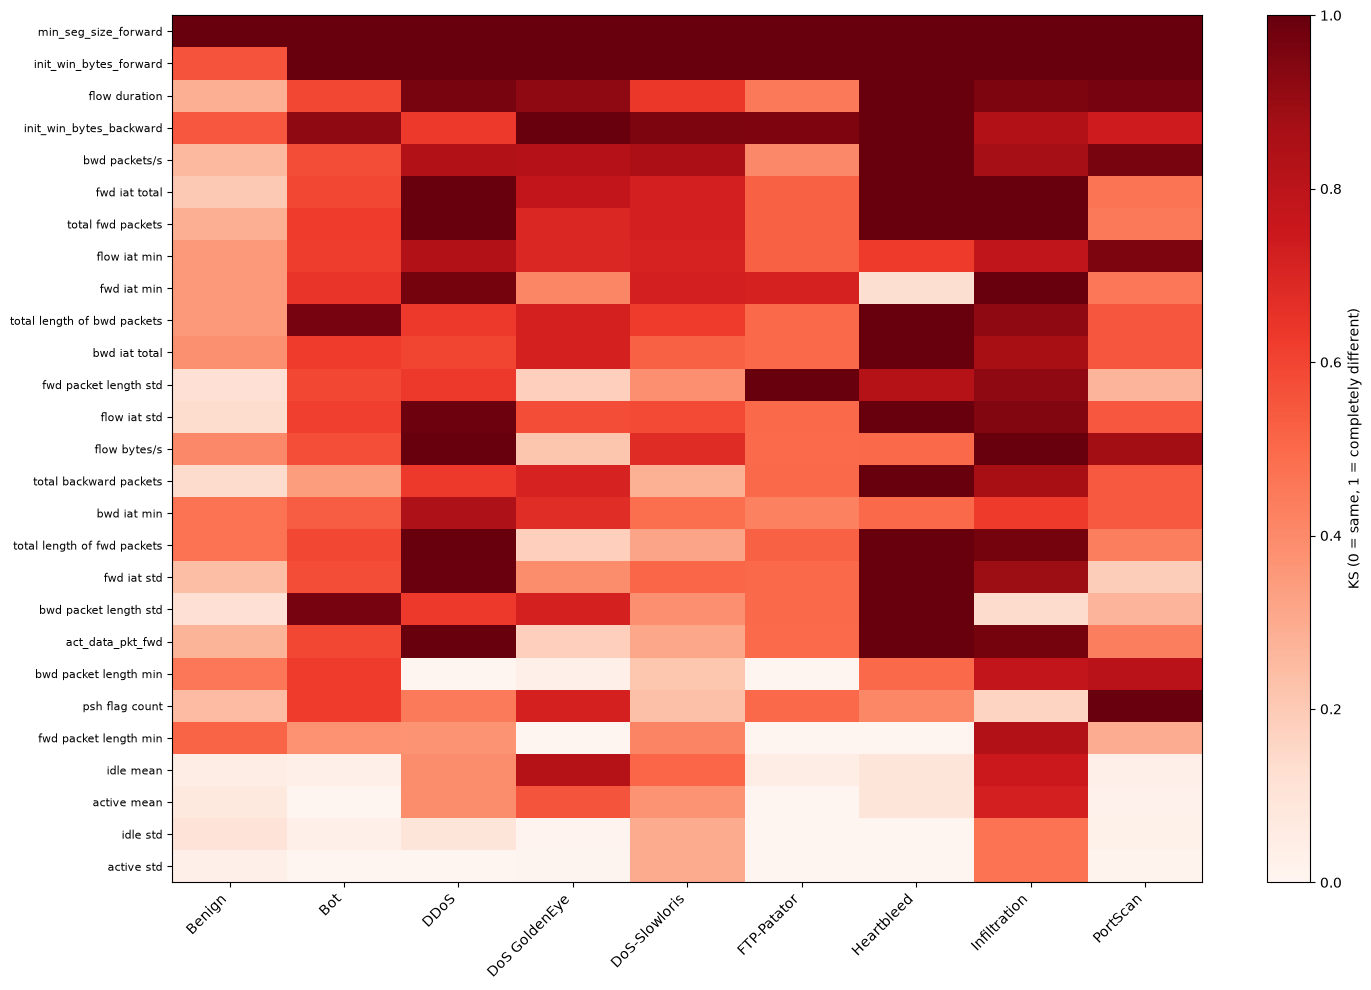

In [75]:
pv = feature_res.pivot(
    index="feature",
    columns="group",
    values="ks"
)

pv = pv.loc[
    pv.median(axis=1).sort_values(ascending=False).index
]

top_n = pv.head(30)

fig, ax = plt.subplots(
    figsize=(1.2 * len(top_n.columns) + 4, 10)
)

im = ax.imshow(
    top_n.values,
    aspect="auto",
    cmap="Reds",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(top_n.columns)))
ax.set_xticklabels(top_n.columns, rotation=45, ha="right")

ax.set_yticks(range(len(top_n.index)))
ax.set_yticklabels(top_n.index, fontsize=8)

plt.colorbar(
    im,
    label="KS (0 = same, 1 = completely different)"
)

plt.tight_layout()
plt.show()